# Phase 3 : développement et entraînement du modèle

LogisticRegression {'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 2, 'tfidf__max_features': 20000, 'tfidf__max_df': 0.9, 'clf__C': 5}


LinearSVC {'tfidf__ngram_range': (1, 1), 'tfidf__min_df': 2, 'tfidf__max_features': 50000, 'tfidf__max_df': 1.0, 'clf__C': 0.5}


RandomForest {'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 5, 'tfidf__max_features': 20000, 'clf__n_estimators': 200, 'clf__max_depth': None}


             model  cv_f1_macro  test_acc  test_f1_macro    fit_s
         LinearSVC       0.8530    0.8754         0.8660  11.3665
LogisticRegression       0.8320    0.8628         0.8533  33.3861
      RandomForest       0.7594    0.7890         0.7647 196.3403



Meilleur modèle : LinearSVC

              precision    recall  f1-score   support

          -1      0.833     0.783     0.808      1647
           0      0.852     0.970     0.908      2499
           1      0.921     0.848     0.883      3144

    accuracy                          0.875      7290
   macro avg      0.869     0.867     0.866      7290
weighted avg      0.877     0.875     0.874      7290



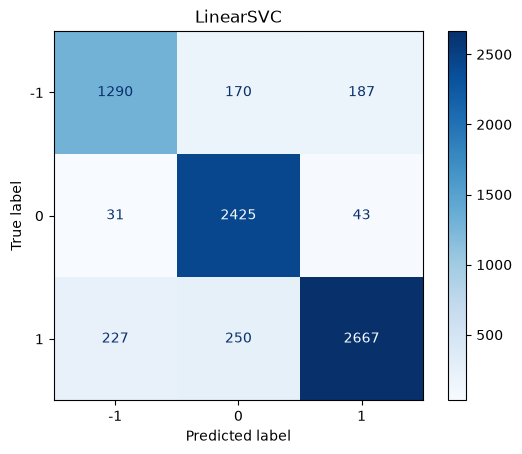

Inférence batch 50 : 2.5 ms (moyenne), 5.8 ms (max)
Accuracy >= 0.80 : True | F1 par classe > 0.75 : True | < 100ms : True


['C:\\Users\\Loubna\\Desktop\\Youtube sentiment analysis\\models\\sentiment_pipeline.joblib']

In [1]:
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
import time, joblib
from pathlib import Path
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SEED = 42
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

train = pd.read_csv(PROC / "train.csv").drop_duplicates()   # retire les doublons du sur-échantillonnage (évite la fuite en CV)
test = pd.read_csv(PROC / "test.csv")
X_tr, y_tr = train["text"].fillna(""), train["category"]
X_te, y_te = test["text"].fillna(""), test["category"]

def tfidf():
    return TfidfVectorizer(sublinear_tf=True, strip_accents="unicode")

candidates = {
    "LogisticRegression": (
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
        {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [2, 5], "tfidf__max_df": [0.9, 1.0],
         "tfidf__max_features": [20000, 50000, None], "clf__C": [0.1, 0.5, 1, 5, 10]}),
    "LinearSVC": (
        LinearSVC(class_weight="balanced", random_state=SEED),
        {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [2, 5], "tfidf__max_df": [0.9, 1.0],
         "tfidf__max_features": [20000, 50000, None], "clf__C": [0.05, 0.1, 0.5, 1, 5]}),
    "RandomForest": (
        RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED),
        {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [5], "tfidf__max_features": [20000],
         "clf__n_estimators": [200, 400], "clf__max_depth": [None, 50]}),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
results, fitted = [], {}
for name, (clf, grid) in candidates.items():
    pipe = Pipeline([("tfidf", tfidf()), ("clf", clf)])
    search = RandomizedSearchCV(pipe, grid, n_iter=8 if name != "RandomForest" else 4, scoring="f1_macro",
                                cv=cv, n_jobs=-1, random_state=SEED, refit=True)
    t0 = time.time(); search.fit(X_tr, y_tr)
    pred = search.predict(X_te)
    results.append({"model": name, "cv_f1_macro": search.best_score_, "test_acc": accuracy_score(y_te, pred),
                    "test_f1_macro": f1_score(y_te, pred, average="macro"), "fit_s": time.time() - t0})
    fitted[name] = search
    print(name, search.best_params_)

res = pd.DataFrame(results).sort_values("test_f1_macro", ascending=False).round(4)
print(res.to_string(index=False))

best_name = res.iloc[0]["model"]
best = fitted[best_name].best_estimator_
pred = best.predict(X_te)
print(f"\nMeilleur modèle : {best_name}\n")
print(classification_report(y_te, pred, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=sorted(y_te.unique())), display_labels=sorted(y_te.unique())).plot(cmap="Blues")
plt.title(best_name); plt.savefig(PROC / "confusion_matrix.png", dpi=120); plt.show()

# temps d'inférence : batch de 50 commentaires
batch = X_te.sample(50, random_state=SEED).tolist()
times = []
for _ in range(20):
    t0 = time.perf_counter(); best.predict(batch); times.append((time.perf_counter() - t0) * 1000)
print(f"Inférence batch 50 : {sum(times)/len(times):.1f} ms (moyenne), {max(times):.1f} ms (max)")

f1s = f1_score(y_te, pred, average=None)
print("Accuracy >= 0.80 :", accuracy_score(y_te, pred) >= 0.80, "| F1 par classe > 0.75 :", bool((f1s > 0.75).all()),
      "| < 100ms :", max(times) < 100)

# sauvegarde : vectoriseur et classifieur séparés + pipeline complet
joblib.dump(best.named_steps["tfidf"], MODELS / "tfidf_vectorizer.joblib")
joblib.dump(best.named_steps["clf"], MODELS / "best_model.joblib")
joblib.dump(best, MODELS / "sentiment_pipeline.joblib")
